In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

In [3]:
df = pd.read_csv('../../Data/food_delivery_orders_dataset.csv')
df_delivered = df[df['order_status'] == 'Completed'].copy()

# Считаем чистую скорость и убираем аномалии
df_delivered['pure_delivery_time'] = df_delivered['actual_delivery_time_minutes'] - df_delivered['restaurant_preparation_time_minutes']
df_delivered['pure_speed_kmh'] = df_delivered['distance_km'] / (df_delivered['pure_delivery_time'] / 60)

df_delivered = df_delivered[
    (df_delivered['pure_delivery_time'] > 0) & 
    (df_delivered['pure_speed_kmh'] <= 60)
].copy()

# 2. Подготовка признаков (X) и цели (y)
features = ['distance_km', 'restaurant_preparation_time_minutes', 'items_count', 'traffic_level', 'weather']
X = df_delivered[features].copy()
y = df_delivered['actual_delivery_time_minutes']

# Кодируем категории
X = pd.get_dummies(X, drop_first=True)

# Разделяем на Train и Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Данные готовы. Размер Train: {X_train.shape}, Test: {X_test.shape}")

Данные готовы. Размер Train: (39131, 8), Test: (9783, 8)


Степень 1: R2 train=0.9337 | R2 test=0.9381
Степень 2: R2 train=0.9706 | R2 test=0.9711
Степень 3: R2 train=0.9710 | R2 test=0.9716
Степень 4: R2 train=0.9711 | R2 test=0.9715
Степень 5: R2 train=0.9712 | R2 test=0.9715


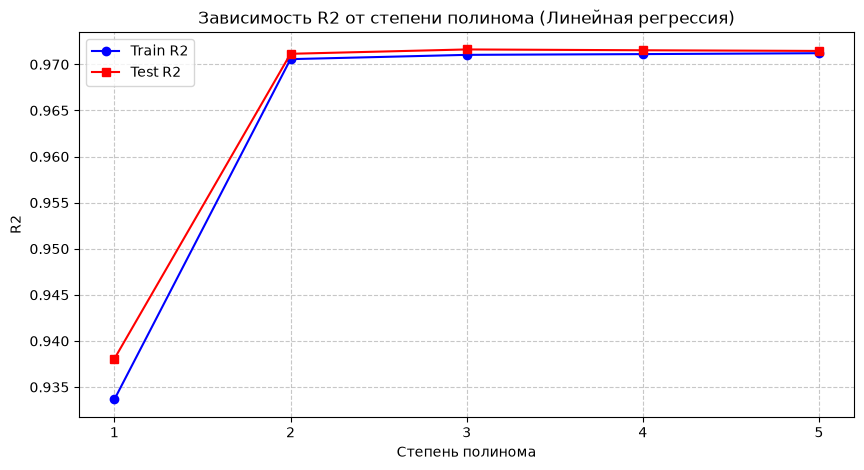

In [13]:
degrees = [1, 2, 3, 4, 5]
train_scores = []
test_scores = []

for d in degrees:
    # Используем пайплайн, чтобы масштабировать данные перед полиномом
    model = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    train_scores.append(r2_score(y_train, y_pred_train))
    test_scores.append(r2_score(y_test, y_pred_test))
    
    print(f"Степень {d}: R2 train={train_scores[-1]:.4f} | R2 test={test_scores[-1]:.4f}")

# Строим график
plt.figure(figsize=(10, 5))
plt.plot(degrees, train_scores, marker='o', label='Train R2', color='blue')
plt.plot(degrees, test_scores, marker='s', label='Test R2', color='red')
plt.title('Зависимость R2 от степени полинома (Линейная регрессия)')
plt.xlabel('Степень полинома')
plt.ylabel('R2')
plt.xticks(degrees)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

alpha=    0.01 | R2 train=0.9706 | R2 test=0.9711
alpha=    0.05 | R2 train=0.9706 | R2 test=0.9711
alpha=    0.22 | R2 train=0.9706 | R2 test=0.9711
alpha=    1.00 | R2 train=0.9706 | R2 test=0.9711
alpha=    4.64 | R2 train=0.9706 | R2 test=0.9711
alpha=   21.54 | R2 train=0.9706 | R2 test=0.9711
alpha=  100.00 | R2 train=0.9704 | R2 test=0.9710
alpha=  464.16 | R2 train=0.9686 | R2 test=0.9691
alpha= 2154.43 | R2 train=0.9579 | R2 test=0.9583
alpha=10000.00 | R2 train=0.9301 | R2 test=0.9314


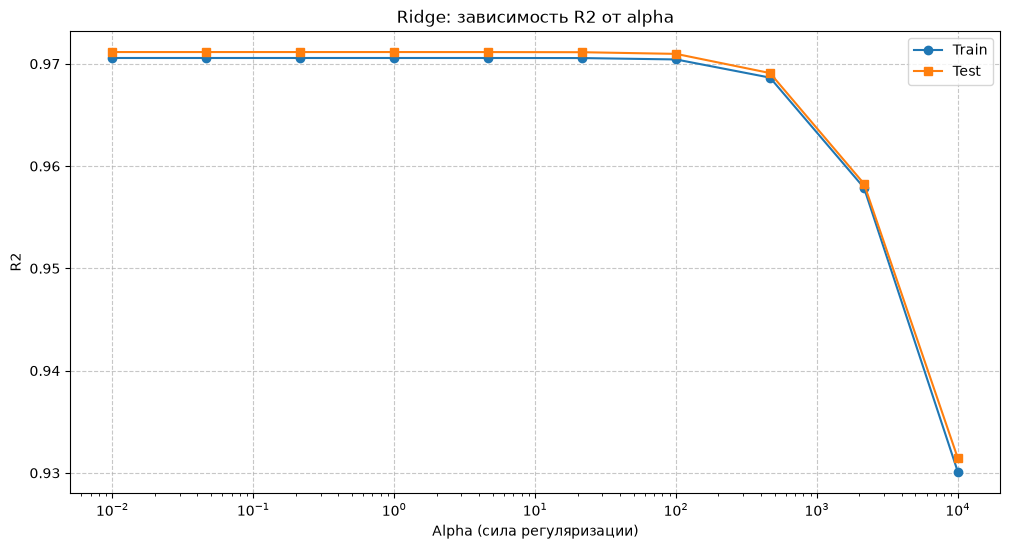


Лучший R2 на тесте: 0.9711 при alpha = 0.01
Соответствующий R2 на трейне: 0.9706

Средний |coef|: 0.9049
Максимальный |coef|: 12.9827
